# Bagging (Bootstrap Aggregating) para clasificación

**Bagging** (*bootstrap aggregating*) fue propuesto por Leo Breiman en 1996. Es la técnica de ensamble más simple: en lugar de entrenar un solo modelo, se entrenan muchos modelos del mismo tipo sobre distintas versiones remuestreadas (bootstrap) del conjunto de entrenamiento, y se combinan sus predicciones.

La idea clave es que un modelo con **mucha varianza y poco sesgo** (como un árbol de decisión profundo, sin restricciones) cambia bastante si se entrena con una muestra de datos ligeramente distinta. Al promediar (o votar, en clasificación) las predicciones de muchos de esos modelos entrenados sobre muestras distintas, las fluctuaciones individuales se cancelan y el modelo combinado resulta mucho más estable, sin aumentar apenas el sesgo.

A diferencia de boosting (AdaBoost, Gradient Boosting), en bagging los modelos se entrenan **de forma independiente y en paralelo** -- ninguno depende del error del anterior.

**Fortalezas** | **Debilidades**
--------------|--------------
Reduce la varianza de modelos inestables (árboles profundos) sin apenas aumentar el sesgo | No ayuda mucho si el modelo base ya tiene poca varianza (sesgo alto)
Los modelos se entrenan en paralelo -- es fácil de paralelizar | Pierde algo de interpretabilidad frente a un único árbol
Permite estimar el error de generalización "gratis" con las muestras out-of-bag (OOB) | Con muchos árboles, el costo de memoria y de predicción crece linealmente con el número de árboles
Menos sensible al sobreajuste que un único árbol profundo | No reduce el sesgo: si el modelo base está sesgado, el ensamble también lo estará

## El algoritmo

Dado un conjunto de entrenamiento $\{(x_i, y_i)\}_{i=1}^n$ y un número $B$ de modelos a entrenar:

**Para $b = 1, \dots, B$:**
1. Generar una muestra *bootstrap* $D_b$ de tamaño $n$, muestreando con reemplazo del conjunto de entrenamiento original.
2. Entrenar un modelo base $h_b$ (normalmente un árbol de decisión sin restricciones) sobre $D_b$.

**Para combinar las predicciones (agregación):**
- En **clasificación**, la predicción final es la clase más votada entre los $B$ modelos:
$$F(x) = \text{moda}\{h_1(x), h_2(x), \dots, h_B(x)\}$$
- En regresión (no es el caso de este notebook) sería el promedio: $F(x) = \frac{1}{B}\sum_{b=1}^B h_b(x)$.

**Un detalle importante del muestreo bootstrap:** al muestrear $n$ puntos con reemplazo de un conjunto de $n$ puntos, la probabilidad de que un punto dado *no* sea elegido ni una sola vez es

$$\left(1 - \frac{1}{n}\right)^n \xrightarrow[n \to \infty]{} e^{-1} \approx 0.368$$

Es decir, en promedio cada árbol se entrena dejando fuera (*out-of-bag*, OOB) alrededor del **36.8%** de los datos de entrenamiento. Esos puntos no vistos por el árbol $h_b$ se pueden usar para evaluarlo, lo que permite estimar el error de generalización del ensamble completo sin necesidad de un conjunto de validación aparte.

## Implementación en Python

In [31]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

### Las piezas del algoritmo

In [32]:
def bootstrap_sample(X, y, rng):
    '''
    Genera una muestra bootstrap: n índices elegidos con reemplazo de
    entre los n puntos de entrenamiento.

    X, y : datos de entrenamiento originales
    rng  : generador de números aleatorios (np.random.default_rng)

    Devuelve
    -------
    X_b, y_b : la muestra bootstrap (mismo tamaño que X, y, con repeticiones)
    oob_idx  : índices de los puntos que NO fueron elegidos (out-of-bag)
    '''
    n = X.shape[0]
    idx = rng.integers(0, n, size=n)          # muestreo CON reemplazo
    oob_idx = np.setdiff1d(np.arange(n), idx)  # los que quedaron fuera
    return X[idx], y[idx], oob_idx

In [33]:
def fit(X, y, n_estimators=50, max_depth=None, random_state=0):
    '''
    Entrena un ensamble de bagging: n_estimators árboles de decisión,
    cada uno sobre su propia muestra bootstrap.

    X, y          : datos de entrenamiento
    n_estimators  : número de árboles (B)
    max_depth     : profundidad máxima de cada árbol (None = sin restricción,
                    que es lo habitual en bagging: queremos modelos con
                    mucha varianza para que el promediado tenga efecto)
    random_state  : semilla para reproducibilidad

    Devuelve
    -------
    trees            : lista de los B árboles entrenados
    oob_indices_list : lista de los índices out-of-bag de cada árbol
    '''
    rng = np.random.default_rng(random_state)
    trees = []
    oob_indices_list = []

    for b in range(n_estimators):
        X_b, y_b, oob_idx = bootstrap_sample(X, y, rng)

        tree = DecisionTreeClassifier(
            max_depth=max_depth,
            random_state=int(rng.integers(0, 1_000_000)),
        )
        tree.fit(X_b, y_b)

        trees.append(tree)
        oob_indices_list.append(oob_idx)

    return trees, oob_indices_list

In [34]:
def predict(X, trees):
    '''
    Combina las predicciones de todos los árboles por voto mayoritario.

    X     : puntos a predecir
    trees : lista de árboles ya entrenados (salida de fit)
    '''
    # preds[b, i] = predicción del árbol b para el punto i
    preds = np.array([tree.predict(X) for tree in trees])

    n_samples = preds.shape[1]
    y_pred = np.empty(n_samples, dtype=preds.dtype)
    for i in range(n_samples):
        votes = Counter(preds[:, i])
        y_pred[i] = votes.most_common(1)[0][0]  # la clase más votada

    return y_pred

In [35]:
def oob_score(X, y, trees, oob_indices_list):
    '''
    Estima la precisión de generalización del ensamble usando únicamente
    las muestras out-of-bag de cada árbol -- sin necesidad de un conjunto
    de prueba separado.

    Para cada punto i del conjunto de entrenamiento, se reúnen los votos
    de todos los árboles que NO lo vieron durante su entrenamiento
    (porque no estaba en su muestra bootstrap), y se compara el voto
    mayoritario de esos árboles con la etiqueta verdadera.

    X, y             : datos de entrenamiento originales
    trees            : lista de árboles entrenados (salida de fit)
    oob_indices_list : lista de índices out-of-bag de cada árbol (salida de fit)
    '''
    n = X.shape[0]
    votes = [Counter() for _ in range(n)]

    for tree, oob_idx in zip(trees, oob_indices_list):
        if len(oob_idx) == 0:
            continue
        preds = tree.predict(X[oob_idx])
        for idx, pred in zip(oob_idx, preds):
            votes[idx][pred] += 1

    correct = 0
    evaluated = 0
    for i in range(n):
        if len(votes[i]) == 0:
            # este punto fue visto por todos los árboles (muy poco probable
            # con B grande); no se puede evaluar en OOB
            continue
        evaluated += 1
        pred_label = votes[i].most_common(1)[0][0]
        if pred_label == y[i]:
            correct += 1

    return correct / evaluated

## Ejemplo de clasificación

In [36]:
# ------------------------------------------------------------------
# Conjunto de datos sintético de clasificación binaria
# ------------------------------------------------------------------
X, y = make_classification(
    n_samples=500,      # 500 observaciones
    n_features=5,       # 5 variables en total
    n_informative=3,    # 3 de ellas realmente útiles
    n_redundant=0,
    n_classes=2,        # objetivo binario
    random_state=999,   # para reproducibilidad
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

In [37]:
# ------------------------------------------------------------------
# Entrenar el ensamble de bagging y predecir sobre el conjunto de prueba
# ------------------------------------------------------------------
n_estimators = 250  # número de árboles del ensamble
trees, oob_indices_list = fit(
    X_train, y_train, n_estimators=n_estimators, max_depth=None, random_state=42
)
y_pred = predict(X_test, trees)

acc_bagging = np.mean(y_pred == y_test)
print('Bagging (%d árboles) -- accuracy en prueba: %.3f' % (n_estimators, acc_bagging))

Bagging (250 árboles) -- accuracy en prueba: 0.880


### Comparación contra un único árbol

La idea de bagging solo tiene sentido si el modelo base es inestable (alta varianza). Comparemos contra un único árbol de decisión sin restricciones, entrenado directamente sobre todos los datos de entrenamiento -- el tipo de modelo que suele sobreajustar.

In [38]:
# ------------------------------------------------------------------
# Referencia (baseline): un solo árbol de decisión sin restricciones
# ------------------------------------------------------------------
single_tree = DecisionTreeClassifier(max_depth=None, random_state=42)
single_tree.fit(X_train, y_train)

acc_single = np.mean(single_tree.predict(X_test) == y_test)
print('Árbol único (sin restricciones) -- accuracy en prueba: %.3f' % acc_single)
print('Bagging (%d árboles)             -- accuracy en prueba: %.3f' % (n_estimators, acc_bagging))

Árbol único (sin restricciones) -- accuracy en prueba: 0.800
Bagging (250 árboles)             -- accuracy en prueba: 0.880


## Error out-of-bag (OOB)

Como vimos en el algoritmo, cada árbol deja fuera en promedio un 36.8% de los datos de entrenamiento. Usando esos puntos out-of-bag podemos estimar el error de generalización del ensamble **sin tocar el conjunto de prueba**. Si el bagging está bien implementado, el accuracy OOB debería ser parecido al accuracy real en el conjunto de prueba.

In [39]:
# ------------------------------------------------------------------
# Precisión OOB, estimada solo con los datos de entrenamiento
# ------------------------------------------------------------------
oob_acc = oob_score(X_train, y_train, trees, oob_indices_list)
print('Accuracy OOB (estimado sin usar el conjunto de prueba): %.3f' % oob_acc)
print('Accuracy real en el conjunto de prueba:                  %.3f' % acc_bagging)

Accuracy OOB (estimado sin usar el conjunto de prueba): 0.940
Accuracy real en el conjunto de prueba:                  0.880


## Efecto del número de árboles

La reducción de varianza de bagging mejora a medida que se agregan más árboles, pero con rendimientos decrecientes: después de cierto número de árboles, agregar más ya no ayuda mucho (a diferencia de boosting, bagging no se sobreajusta por usar demasiados árboles). Veamos cómo cambian el accuracy en prueba y el accuracy OOB conforme crece $B$.

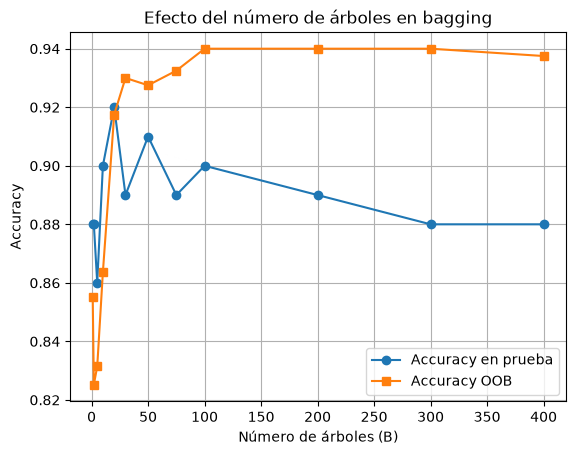

In [40]:
# ------------------------------------------------------------------
# Accuracy (prueba y OOB) en función del número de árboles B
# ------------------------------------------------------------------
Bs = [1, 2, 5, 10, 20, 30, 50, 75, 100, 200, 300, 400]
test_accs = []
oob_accs = []

for B in Bs:
    trees_b, oob_b = fit(X_train, y_train, n_estimators=B, max_depth=None, random_state=42)
    test_accs.append(np.mean(predict(X_test, trees_b) == y_test))
    oob_accs.append(oob_score(X_train, y_train, trees_b, oob_b))

plt.plot(Bs, test_accs, 'o-', label='Accuracy en prueba')
plt.plot(Bs, oob_accs, 's-', label='Accuracy OOB')
plt.xlabel('Número de árboles (B)')
plt.ylabel('Accuracy')
plt.title('Efecto del número de árboles en bagging')
plt.legend()
plt.grid()

## Ejemplo ilustrado: cómo bagging suaviza la frontera de decisión

Para visualizar el efecto de bagging, usamos un conjunto de datos en 2D (dos variables, para poder graficar la frontera de decisión directamente). Comparamos:

- La frontera de decisión de un **único árbol** sin restricciones: muy irregular, ajustada al ruido de los datos de entrenamiento (varianza alta).
- La frontera de decisión del **ensamble de bagging**: resultado de promediar (votar) sobre muchas fronteras irregulares distintas, cada una ajustada a una muestra bootstrap diferente. El resultado es una frontera mucho más suave y estable.

In [41]:
# ------------------------------------------------------------------
# Conjunto de datos 2D, solo para poder graficar la frontera de decisión.
# Se usa un conjunto más "ruidoso" (clusters solapados, algo de ruido en
# las etiquetas) para que el sobreajuste del árbol único sea visible.
# ------------------------------------------------------------------
X2, y2 = make_classification(
    n_samples=200,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=2,
    class_sep=0.8,
    flip_y=0.08,
    random_state=7,
)

single_2d = DecisionTreeClassifier(max_depth=None, random_state=1)
single_2d.fit(X2, y2)

trees_2d, _ = fit(X2, y2, n_estimators=100, max_depth=None, random_state=1)

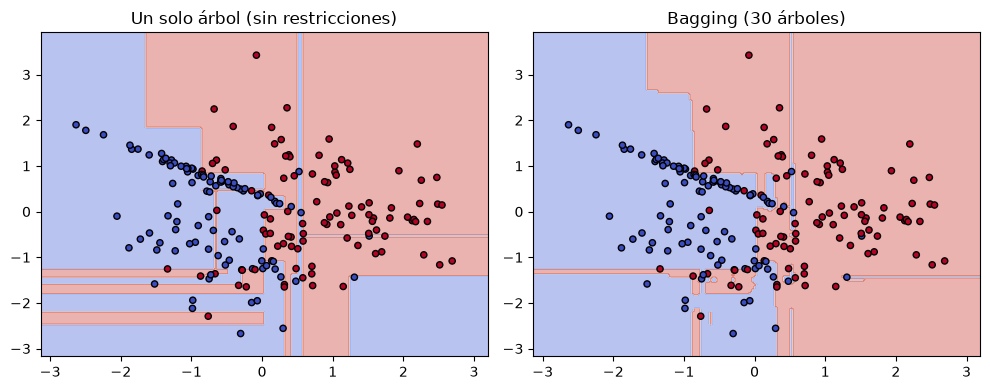

In [42]:
# ------------------------------------------------------------------
# Graficar ambas fronteras de decisión sobre una malla (meshgrid)
# ------------------------------------------------------------------
xx, yy = np.meshgrid(
    np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 200),
    np.linspace(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5, 200),
)
grid = np.c_[xx.ravel(), yy.ravel()]

Z_single = single_2d.predict(grid).reshape(xx.shape)
Z_bagging = predict(grid, trees_2d).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].contourf(xx, yy, Z_single, alpha=0.4, cmap='coolwarm')
axes[0].scatter(X2[:, 0], X2[:, 1], c=y2, edgecolor='k', s=20, cmap='coolwarm')
axes[0].set_title('Un solo árbol (sin restricciones)')

axes[1].contourf(xx, yy, Z_bagging, alpha=0.4, cmap='coolwarm')
axes[1].scatter(X2[:, 0], X2[:, 1], c=y2, edgecolor='k', s=20, cmap='coolwarm')
axes[1].set_title('Bagging (30 árboles)')

plt.tight_layout()

## Comparación con la implementación de scikit-learn

Por último, comparamos nuestra implementación "desde cero" contra `BaggingClassifier` de scikit-learn, usando el mismo número de árboles. Los resultados deberían ser muy parecidos (no idénticos, porque scikit-learn usa su propia semilla interna para las muestras bootstrap).

In [43]:
# ------------------------------------------------------------------
# Comparación con sklearn.ensemble.BaggingClassifier
# ------------------------------------------------------------------
from sklearn.ensemble import BaggingClassifier

sklearn_bagging = BaggingClassifier(n_estimators=n_estimators, random_state=42)
sklearn_bagging.fit(X_train, y_train)
acc_sklearn = np.mean(sklearn_bagging.predict(X_test) == y_test)

print('Nuestra implementación -- accuracy en prueba: %.3f' % acc_bagging)
print('BaggingClassifier (sklearn) -- accuracy en prueba: %.3f' % acc_sklearn)

Nuestra implementación -- accuracy en prueba: 0.880
BaggingClassifier (sklearn) -- accuracy en prueba: 0.890
